In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataprep import load_views

In [2]:
views = load_views()
v = views.frame

In [3]:
wk = v.groupby(['s', 'week']).size().unstack(fill_value=0)
first = v.groupby('s').week.min()
tot = v.groupby('week').size()

In [4]:
v['first'] = v.s.map(first)
(v['first'] == v.week).groupby(v.week).mean().round(3)

week
0     1.000
1     0.043
2     0.030
3     0.023
4     0.019
5     0.027
6     0.017
7     0.024
8     0.019
9     0.018
10    0.032
11    0.015
12    0.014
13    0.018
dtype: float64

In [5]:
share = wk.div(tot, axis=1)

hits = []
for s in wk.index:
    f0 = first[s]
    if f0 < 2 or f0 > 10:
        continue

    top50 = np.sort(wk[f0].values)[-50]
    if (wk.loc[s, f0:f0 + 3] >= top50).any():
        hits.append(s)

len(hits)

11

In [6]:
rows = []
for s in hits:
    f0 = first[s]

    for k in range(-1, 4):
        w = f0 + k
        if w < 0 or w > 13:
            continue

        actual = share.loc[s, w]
        seen = share.loc[s, w - 1] if w - 1 >= 0 else 0
        rows.append((s, k, actual, seen))

d = pd.DataFrame(rows, columns=['s', 'k', 'actual', 'pop_1w'])
m = d.groupby('k')[['actual', 'pop_1w']].mean() * 100
m

,actual,pop_1w
k,,
-1,0.000000,0.000000
0,0.292055,0.000000
1,0.461849,0.292055
2,0.517044,0.461849
3,0.492650,0.517044


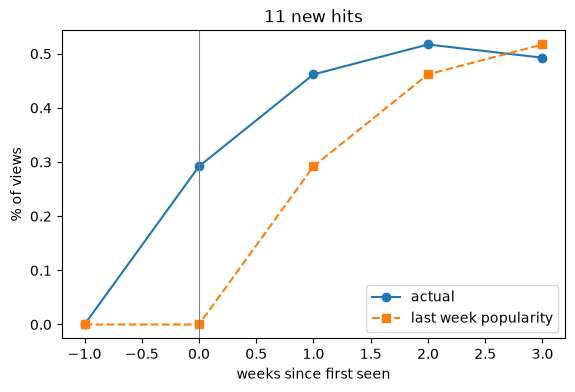

In [7]:
plt.figure(figsize=(6.5, 4))

plt.plot(m.index, m.actual, 'o-', label='actual')
plt.plot(m.index, m.pop_1w, 's--', label='last week popularity')

plt.axvline(0, color='grey', lw=.8)
plt.xlabel('weeks since first seen')
plt.ylabel('% of views')
plt.title(f'{len(hits)} new hits')
plt.legend()
plt.show()